# 01 Initial EDA — Olist

**Mục tiêu:** Xem nhanh dữ liệu gốc trước khi làm sạch và ghép bảng. Target của nhóm là `freight_value`.

Chỉ kiểm tra chất lượng, phân phối và vài mối quan hệ cơ bản. **Chưa sửa hay xóa dữ liệu.**

### 1. Đọc dữ liệu

Mỗi bảng có một ý nghĩa riêng. Đặc biệt, `items` là **dòng hàng**, không phải một đơn hàng.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

path = "../data/raw/"

orders = pd.read_csv(path + "olist_orders_dataset.csv")
items = pd.read_csv(path + "olist_order_items_dataset.csv")
customers = pd.read_csv(path + "olist_customers_dataset.csv")
sellers = pd.read_csv(path + "olist_sellers_dataset.csv")
products = pd.read_csv(path + "olist_products_dataset.csv")
payments = pd.read_csv(path + "olist_order_payments_dataset.csv")
reviews = pd.read_csv(path + "olist_order_reviews_dataset.csv")
translation = pd.read_csv(path + "product_category_name_translation.csv")

geo = pd.read_csv(path + "olist_geolocation_dataset.csv", sep=",", encoding_errors="replace")

raw = {
    "orders": orders,
    "items": items,
    "customers": customers,
    "sellers": sellers,
    "products": products,
    "payments": payments,
    "reviews": reviews,
    "geolocation": geo,
    "translation": translation
}

for name, df in raw.items():
    print(name, df.shape)

orders (99441, 8)
items (112650, 7)
customers (99441, 5)
sellers (3095, 4)
products (32951, 9)
payments (103886, 5)
reviews (99224, 7)
geolocation (1000163, 5)
translation (71, 2)


### 2. Chất lượng dữ liệu ban đầu

Kiểm tra missing và dòng trùng hoàn toàn. Số dòng trùng **chưa có nghĩa phải xóa**.

In [12]:
for name, df in raw.items():
    print(
        name,
        "| missing:", df.isna().sum().sum(),
        "| full duplicates:", df.duplicated().sum()
    )

orders | missing: 4908 | full duplicates: 0
items | missing: 0 | full duplicates: 0
customers | missing: 0 | full duplicates: 0
sellers | missing: 0 | full duplicates: 0
products | missing: 2448 | full duplicates: 0
payments | missing: 0 | full duplicates: 0
reviews | missing: 145903 | full duplicates: 0
geolocation | missing: 0 | full duplicates: 261831
translation | missing: 0 | full duplicates: 0


**Kiểm tra khóa ứng viên:** Đếm số khóa trùng trước khi quyết định grain. Riêng `geolocation` có nhiều dòng trên cùng ZIP nên không dùng ZIP làm khóa duy nhất.

In [13]:
print("orders:", orders.duplicated(subset=["order_id"]).sum())
print("items:", items.duplicated(subset=["order_id", "order_item_id"]).sum())
print("customers:", customers.duplicated(subset=["customer_id"]).sum())
print("sellers:", sellers.duplicated(subset=["seller_id"]).sum())
print("products:", products.duplicated(subset=["product_id"]).sum())
print("payments:", payments.duplicated(subset=["order_id", "payment_sequential"]).sum())
print("reviews (review_id):", reviews.duplicated(subset=["review_id"]).sum())
print("translation:", translation.duplicated(subset=["product_category_name"]).sum())

orders: 0
items: 0
customers: 0
sellers: 0
products: 0
payments: 0
reviews (review_id): 814
translation: 0


**Nhận xét:** Không xóa theo `order_id` trong `items`. Với `reviews`, `review_id` cần kiểm tra thêm vì không duy nhất trong file gốc.

### 3. Orders — trạng thái đơn hàng

Bảng này theo `order_id`. Mình xem đơn giao thành công chiếm bao nhiêu, và ngày giao thiếu bao nhiêu.

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
Missing delivered date: 2965


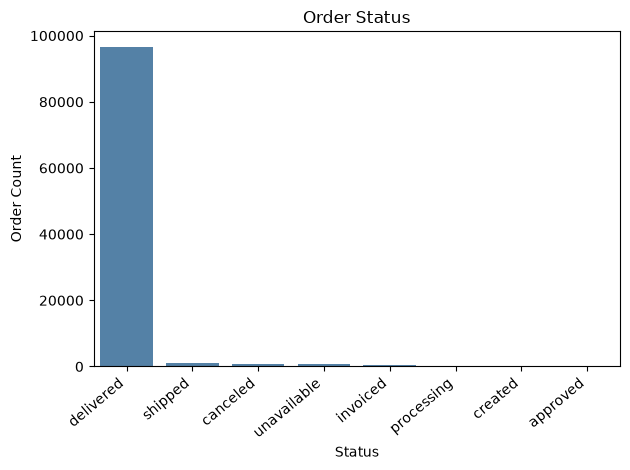

In [14]:
print(orders["order_status"].value_counts())
print("Missing delivered date:", orders["order_delivered_customer_date"].isna().sum())

sns.countplot(data=orders, x="order_status", order=orders["order_status"].value_counts().index, color="steelblue")
plt.title("Order Status")
plt.xlabel("Status")
plt.ylabel("Order Count")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

**Nhận xét:** Phần lớn đơn ở trạng thái `delivered`. Ngày giao bị thiếu không phải lúc nào cũng là lỗi (ví dụ đơn chưa được giao).

### 4. Items — phí vận chuyển (target)

Mình xem Mean, Median, IQR rồi mới nhận xét outliers.

In [15]:
print(items[["price", "freight_value"]].describe().round(2))
print("Freight = 0:", (items["freight_value"] == 0).sum())

q1 = items["freight_value"].quantile(0.25)
q3 = items["freight_value"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = (
    (items["freight_value"] < lower) |
    (items["freight_value"] > upper)
)

print("IQR:", round(iqr, 2))
print("Lower:", round(lower, 2), "| Upper:", round(upper, 2))
print("Outliers:", outliers.sum())
print("Outlier rate (%):", round(outliers.sum() / items["freight_value"].count() * 100, 2))

           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max      6735.00         409.68
Freight = 0: 383
IQR: 8.07
Lower: 0.98 | Upper: 33.25
Outliers: 12134
Outlier rate (%): 10.77


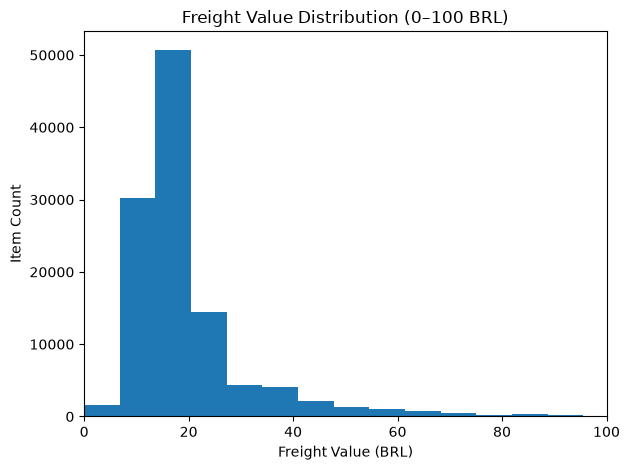

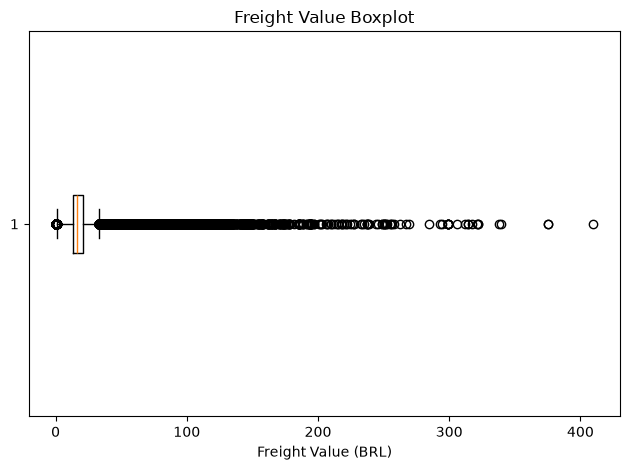

In [16]:
plt.hist(items["freight_value"], bins=60)
plt.xlim(0, 100)
plt.title("Freight Value Distribution (0–100 BRL)")
plt.xlabel("Freight Value (BRL)")
plt.ylabel("Item Count")
plt.tight_layout()
plt.show()

plt.boxplot(items["freight_value"].dropna(), orientation="horizontal")
plt.title("Freight Value Boxplot")
plt.xlabel("Freight Value (BRL)")
plt.tight_layout()
plt.show()

**Nhận xét:** Phí vận chuyển lệch phải; Mean lớn hơn Median. Outlier theo IQR chưa chắc là lỗi. Trục Histogram chỉ phóng to 0–100 BRL, không bỏ các dòng phía trên.

### 5. Items — giá và phí vận chuyển

Xem Scatterplot rồi kiểm tra Pearson / Spearman.

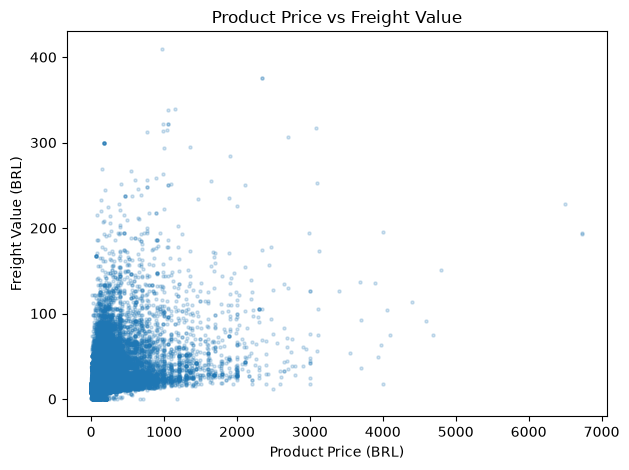

Pearson: 0.4142
Spearman: 0.4342


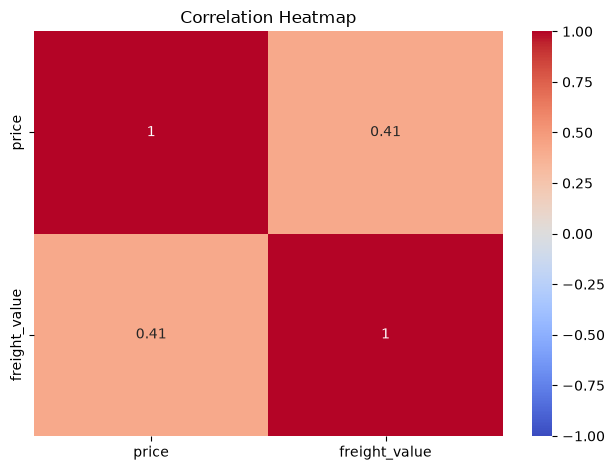

In [17]:
plt.scatter(items["price"], items["freight_value"], alpha=0.2, s=5)
plt.title("Product Price vs Freight Value")
plt.xlabel("Product Price (BRL)")
plt.ylabel("Freight Value (BRL)")
plt.tight_layout()
plt.show()

print("Pearson:", round(items["price"].corr(items["freight_value"], method="pearson"), 4))
print("Spearman:", round(items["price"].corr(items["freight_value"], method="spearman"), 4))

corr_matrix = items[["price", "freight_value"]].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**Nhận xét:** Hai biến có tương quan dương, nhưng các điểm phân tán khá rộng. Tương quan không nói lên nguyên nhân.

### 6. Items — Top 5 seller

So sánh số dòng hàng với phí ship trung bình và trung vị.

                                  count   mean  median
seller_id                                             
1f50f920176fa81dab994f9023523100   1931  18.21   17.66
4a3ca9315b744ce9f8e9374361493884   1987  17.65   15.70
6560211a19b47992c3666cc44a7e94c0   2033  13.75   14.10
cc419e0650a3c5ba77189a1882b7556a   1775  14.46   14.34
da8622b14eb17ae2831f4ac5b9dab84a   1551  16.09   15.10


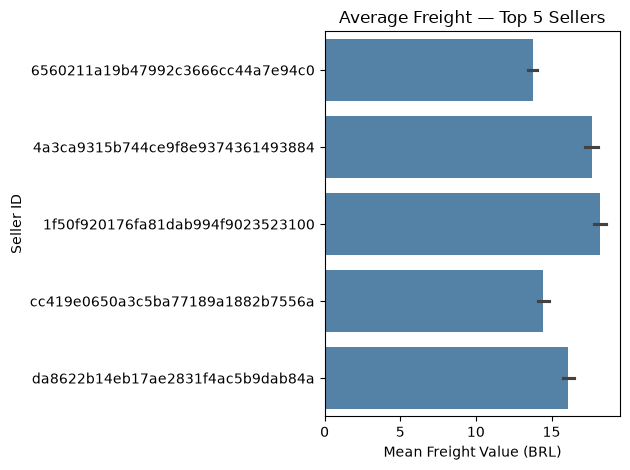

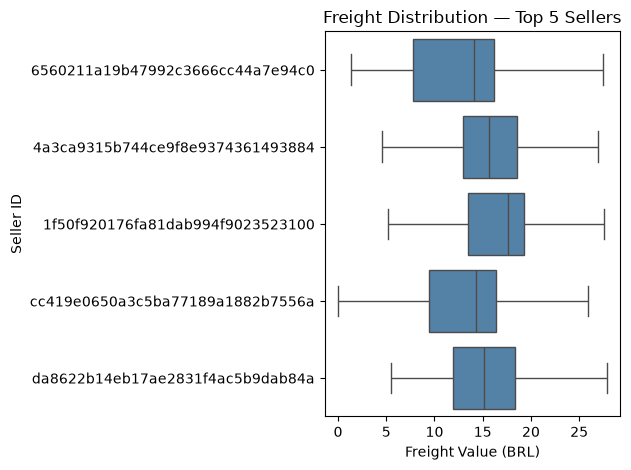

In [18]:
top5 = items["seller_id"].value_counts().head(5).index
top5_items = items[items["seller_id"].isin(top5)]

summary = (
    top5_items.groupby("seller_id")["freight_value"]
    .agg(["count", "mean", "median"])
).round(2)
print(summary)

sns.barplot(data=top5_items, y="seller_id", x="freight_value", order=top5, color="steelblue")
plt.title("Average Freight — Top 5 Sellers")
plt.xlabel("Mean Freight Value (BRL)")
plt.ylabel("Seller ID")
plt.tight_layout()
plt.show()

sns.boxplot(data=top5_items, y="seller_id", x="freight_value", order=top5, showfliers=False, color="steelblue")
plt.title("Freight Distribution — Top 5 Sellers")
plt.xlabel("Freight Value (BRL)")
plt.ylabel("Seller ID")
plt.tight_layout()
plt.show()

**Nhận xét:** Seller có nhiều dòng hàng chưa chắc có Mean Freight cao nhất. Boxplot giúp nhìn Median và IQR; `showfliers=False` chỉ ẩn chấm trên hình.

### 7. Products — thông tin sản phẩm

Xem trọng lượng và mức độ thiếu dữ liệu. Đây là **số sản phẩm trong catalog**, chưa phải số lần bán.

       product_weight_g  product_length_cm  product_height_cm  \
count          32949.00           32949.00           32949.00   
mean            2276.47              30.82              16.94   
std             4282.04              16.91              13.64   
min                0.00               7.00               2.00   
25%              300.00              18.00               8.00   
50%              700.00              25.00              13.00   
75%             1900.00              38.00              21.00   
max            40425.00             105.00             105.00   

       product_width_cm  
count          32949.00  
mean              23.20  
std               12.08  
min                6.00  
25%               15.00  
50%               20.00  
75%               30.00  
max              118.00  
Missing category: 610
Missing weight: 2
Top categories:
product_category_name
cama_mesa_banho          3029
esporte_lazer            2867
moveis_decoracao         2657
beleza_saude

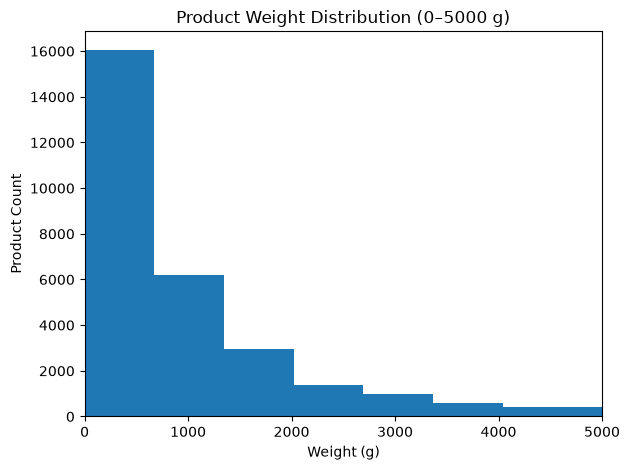

In [19]:
print(products[["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]].describe().round(2))
print("Missing category:", products["product_category_name"].isna().sum())
print("Missing weight:", products["product_weight_g"].isna().sum())
print("Top categories:")
print(products["product_category_name"].value_counts().head(5))

plt.hist(products["product_weight_g"].dropna(), bins=60)
plt.xlim(0, 5000)
plt.title("Product Weight Distribution (0–5000 g)")
plt.xlabel("Weight (g)")
plt.ylabel("Product Count")
plt.tight_layout()
plt.show()

**Nhận xét:** Trọng lượng cũng có các giá trị rất lớn. Biểu đồ đang phóng to 0–5.000 g; chưa xóa sản phẩm nặng.

### 8. Customers — khách hàng ở bang nào?

Đếm theo `customer_state`. `customer_id` và `customer_unique_id` là hai khái niệm khác nhau.

Customer IDs: 99441


Unique customers: 96096
customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
Name: count, dtype: int64


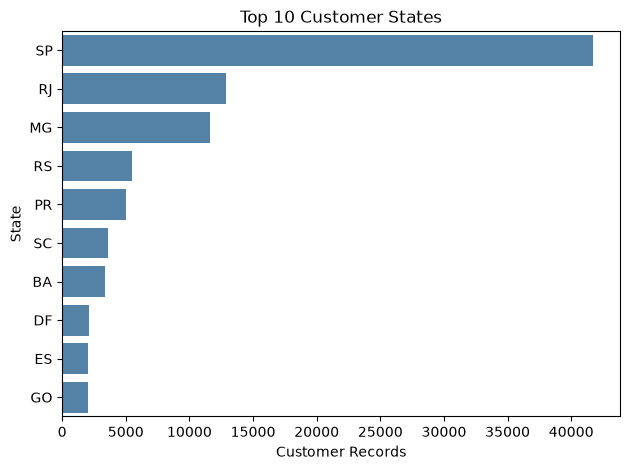

In [20]:
print("Customer IDs:", customers["customer_id"].nunique())
print("Unique customers:", customers["customer_unique_id"].nunique())
print(customers["customer_state"].value_counts().head(5))

top_states = customers["customer_state"].value_counts().head(10).index
sns.countplot(data=customers, y="customer_state", order=top_states, color="steelblue")
plt.title("Top 10 Customer States")
plt.xlabel("Customer Records")
plt.ylabel("State")
plt.tight_layout()
plt.show()

**Nhận xét:** Số dòng `customers` không đồng nghĩa số khách duy nhất. Các bang xuất hiện nhiều nên được kiểm tra thêm khi phân tích vận chuyển.

### 9. Sellers — người bán ở bang nào?

Sellers: 3095
seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
Name: count, dtype: int64


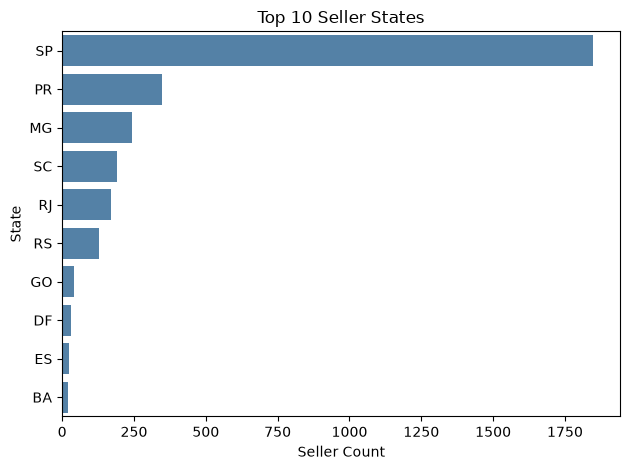

In [21]:
print("Sellers:", sellers["seller_id"].nunique())
print(sellers["seller_state"].value_counts().head(5))

top_seller_states = sellers["seller_state"].value_counts().head(10).index
sns.countplot(data=sellers, y="seller_state", order=top_seller_states, color="steelblue")
plt.title("Top 10 Seller States")
plt.xlabel("Seller Count")
plt.ylabel("State")
plt.tight_layout()
plt.show()

**Nhận xét:** Phân bố seller và customer khác nhau có thể liên quan đến tuyến vận chuyển. Chưa tính khoảng cách ở EDA ban đầu.

### 10. Geolocation — dữ liệu tọa độ

Mình chỉ xem cấu trúc ở bước này. File đang có tọa độ dạng chuỗi nhiều dấu chấm, **chưa đủ an toàn để tính distance**.

In [22]:
print("Rows:", geo.shape[0])
print("Unique ZIP:", geo["geolocation_zip_code_prefix"].nunique())
print("Full duplicates:", geo.duplicated().sum())
print(geo[["geolocation_lat", "geolocation_lng"]].dtypes)
print(geo[["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"]].head(5))

Rows: 1000163
Unique ZIP: 19015
Full duplicates: 261831
geolocation_lat    float64
geolocation_lng    float64
dtype: object
   geolocation_zip_code_prefix  geolocation_lat  geolocation_lng
0                         1037       -23.545621       -46.639292
1                         1046       -23.546081       -46.644820
2                         1046       -23.546129       -46.642951
3                         1041       -23.544392       -46.639499
4                         1035       -23.541578       -46.641607


**Nhận xét:** Một ZIP có nhiều tọa độ là chuyện có thể xảy ra. File này cần kiểm tra định dạng trước khi ghép và dùng lat/lng.

### 11. Payments — hình thức thanh toán

Một đơn có thể có nhiều bản ghi payment, nên số dòng payments không nhất thiết bằng số đơn.

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64
count    103886.00
mean        154.10
std         217.49
min           0.00
25%          56.79
50%         100.00
75%         171.84
max       13664.08
Name: payment_value, dtype: float64


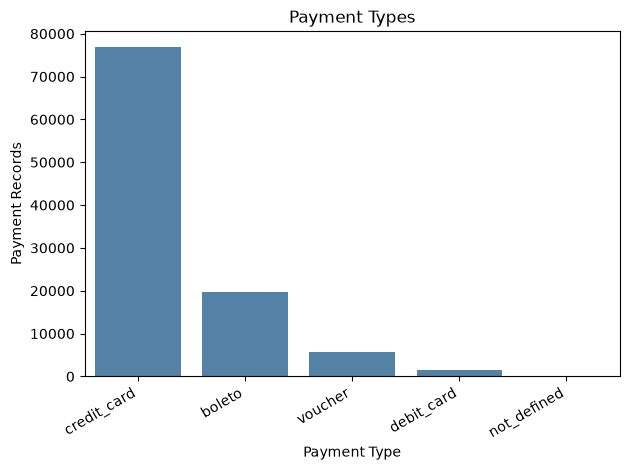

In [23]:
print(payments["payment_type"].value_counts())
print(payments["payment_value"].describe().round(2))

sns.countplot(data=payments, x="payment_type", order=payments["payment_type"].value_counts().index, color="steelblue")
plt.title("Payment Types")
plt.xlabel("Payment Type")
plt.ylabel("Payment Records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Nhận xét:** `credit_card` phổ biến nhất. Đây là số bản ghi thanh toán, không phải số đơn duy nhất theo từng hình thức.

### 12. Reviews — điểm đánh giá

Xem phân bố điểm và số nhận xét bị thiếu.

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64
Missing comment: 58247
Duplicate review_id: 814


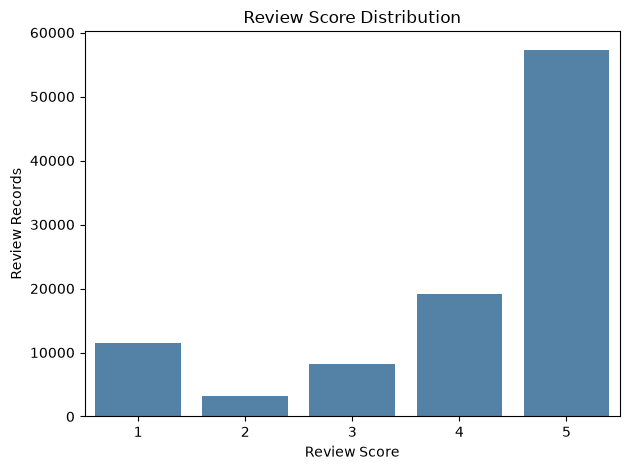

In [24]:
print(reviews["review_score"].value_counts().sort_index())
print("Missing comment:", reviews["review_comment_message"].isna().sum())
print("Duplicate review_id:", reviews.duplicated(subset=["review_id"]).sum())

sns.countplot(data=reviews, x="review_score", color="steelblue")
plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Review Records")
plt.tight_layout()
plt.show()

**Nhận xét:** Điểm 5 xuất hiện nhiều nhất. Thiếu comment không có nghĩa là không có điểm đánh giá; `review_id` trùng cần được kiểm tra ở bước sau.

### 13. Category Translation — đối chiếu danh mục

Kiểm tra tên category của `products` có tìm thấy trong bảng dịch không.

In [25]:
print("Translation rows:", translation.shape[0])
print("Duplicate category names:", translation.duplicated(subset=["product_category_name"]).sum())

not_mapped = products[
    products["product_category_name"].notna() &
    ~products["product_category_name"].isin(translation["product_category_name"])
]

print("Products with unmapped categories:", not_mapped.shape[0])
print(not_mapped["product_category_name"].value_counts())

Translation rows: 71
Duplicate category names: 0
Products with unmapped categories: 13
product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64


**Nhận xét:** Có vài category chưa được dịch. Phần này khác với những sản phẩm vốn đã thiếu `product_category_name`.

### 14. Kết luận nhanh

| Phát hiện | Việc cần kiểm tra tiếp |
|---|---|
| `freight_value` lệch phải, có nhiều outliers IQR | Kiểm tra đơn, cân nặng, kích thước, tuyến vận chuyển |
| `price` tương quan dương với `freight_value` | Xem thêm các biến khác sau khi join |
| `items` khác grain với `orders` | Join đúng khóa, theo dõi số dòng |
| `products` có category thiếu / chưa được dịch | Phân biệt missing với mapping chưa có |
| `reviews` có `review_id` lặp | Xác minh bản ghi trước khi xử lý |
| Tọa độ `geolocation` có định dạng bất thường | Sửa và kiểm chứng tọa độ rồi mới tính distance |

**Dừng ở đây:** EDA ban đầu của 9 bảng raw. Chưa Cleaning, chưa Join, chưa tạo feature, chưa Modeling.